# 02 · Librerías, constantes, instancias y estado

Los estados del firmware cambian en memoria a lo largo de cada ciclo. NVS es la parte persistente del cursor. La pantalla tiene una paleta RGB565 y conserva los valores dibujados para reducir actualizaciones.

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](01_fundamentos_cpp_y_sintaxis.ipynb) · [Siguiente](03_arranque_conexion_y_tiempo.ipynb)

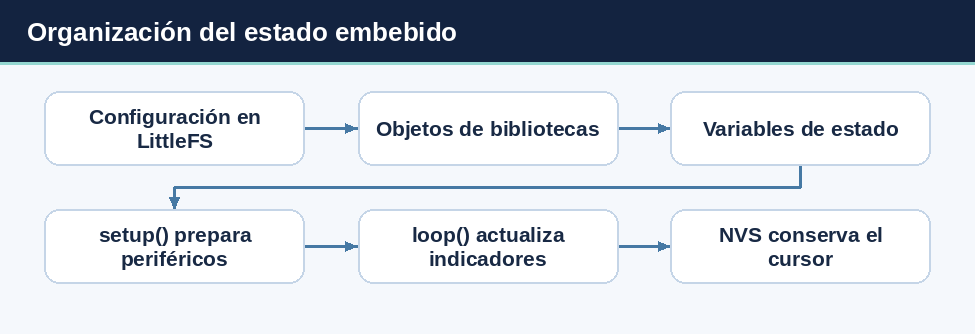

## Bibliotecas del firmware

| Include | Para qué se usa en este proyecto |
|---|---|
| `Arduino.h` | `Serial`, `String`, tipos Arduino, `millis`, `delay` y acceso al ADC del framework ESP32. |
| `ArduinoJson.h` | `JsonDocument`, `JsonObject`, lectura de configuración y serialización del JSON. |
| `DHT.h` | Clase `DHT`, constante `DHT11`, temperatura y humedad. |
| `LittleFS.h` | Objeto `LittleFS` y clase `File` para configuración y CSV en flash. |
| `Preferences.h` | Clase `Preferences`, almacenamiento NVS para el cursor confirmado. |
| `PubSubClient.h` | Cliente MQTT sobre el transporte TCP de Arduino. |
| `TFT_eSPI.h` | Clase `TFT_eSPI`, texto y colores de pantalla. |
| `WiFi.h` | Conexión inalámbrica y transporte `WiFiClient`. |
| `math.h` | `NAN`, `isfinite`, `powf` para validar y calcular concentraciones. |
| `time.h` | `time`, `localtime_r`, `strftime` y tipos de fecha/hora. |

`esp_random()` pertenece al entorno ESP32 y produce los componentes del identificador del registro.
No se usa una librería MQ135: la curva y la compensación se calculan explícitamente en `readGasPpm()`.
No hay LCD I2C, `Wire` ni `LiquidCrystal_I2C` en el firmware actual.

## Cada constante del firmware

| Nombre | Tipo y valor | Significado y uso |
|---|---|---|
| `PIN_DHT` | `uint8_t`, 4 | Entrada de datos del DHT11. |
| `PIN_MQ135` | `uint8_t`, 5 | Entrada ADC del MQ135, después del divisor de tensión. |
| `SAMPLE_INTERVAL_MS` | `unsigned long`, 2000 | Tiempo mínimo entre inicios de muestreo. |
| `CONNECTION_RETRY_INTERVAL_MS` | `unsigned long`, 5000 | Separación entre intentos de reconexión. |
| `CSV_RETRY_INTERVAL_MS` | `unsigned long`, 5000 | Separación entre envíos/reintentos de filas guardadas y revisión de borrado. |
| `MIN_FREE_STORAGE_BYTES` | `size_t`, 8192 | Margen que debe quedar antes de intentar una nueva escritura; no es una garantía de escritura. |
| `ADC_SAMPLE_COUNT` | `unsigned int`, 32 | Cantidad de lecturas ADC promediadas por lectura de gas. |
| `REFERENCE_SAMPLE_COUNT` | `unsigned int`, 30 | Lecturas válidas para estimar la resistencia de referencia. |
| `MQ_SUPPLY_VOLTAGE` | `float`, 5.0 | Alimentación usada para reconstruir la resistencia del sensor. |
| `MQ_REFERENCE_PPM` | `float`, 450.0 | Concentración SUPUESTA del ambiente durante la referencia. |
| `MQ_CURVE_A` | `float`, 110.47 | Coeficiente multiplicativo de la curva aproximada. |
| `MQ_CURVE_B` | `float`, -2.862 | Exponente de la curva aproximada. |
| `DEVICE_ID` | `char[]`, `ESP32_S3_0001` | Identidad MQTT y del JSON; debe ser distinta por placa. |
| `CSV_PATH` | `char[]`, `/pending.csv` | Ruta del único archivo de cola en LittleFS. |
| `CSV_HEADER` | `char[]` | Cabecera exacta de siete columnas terminada en salto de línea. |

`DHT11`, `ADC_11db`, `WIFI_STA`, `WL_CONNECTED`, `TFT_BLACK` y `TFT_WHITE` provienen de las
bibliotecas: seleccionan modelo, atenuación ADC, modo WiFi, estado conectado y colores.
La atenuación ADC no reemplaza el divisor físico ni permite aplicar 5 V a un GPIO.

## Clases e instancias globales

| Declaración | Constructor/argumentos | Responsabilidad |
|---|---|---|
| `TFT_eSPI display` | Constructor sin argumentos explícitos | Representa la pantalla configurada por macros. |
| `DHT dhtSensor(PIN_DHT, DHT11)` | Pin y tipo DHT11 | Acceso al sensor digital. |
| `WiFiClient wifiClient` | Constructor por defecto | Transporte TCP usado por MQTT. |
| `PubSubClient mqttClient(wifiClient)` | Referencia al transporte | Protocolo MQTT; no inicia por sí solo WiFi. |
| `JsonDocument configuration` | Documento inicialmente vacío | Conserva la configuración deserializada. |
| `Preferences queuePreferences` | Objeto NVS; se abre luego con `begin` | Persiste la posición confirmada. |

Los objetos locales `File`, `JsonDocument` y `JsonObject` se crean en las funciones cuando son
necesarios. `JsonObject` es una vista de un objeto dentro de un documento; no equivale a una
copia independiente de todo el documento JSON.

## Topics constantes

`deviceTopicPrefix` concatena `"dispositivo/"` con `DEVICE_ID`. `rawTopic`, `processedTopic`,
`acknowledgmentTopic` y `statusTopic` añaden `/crudo`, `/tratado`, `/ack` y `/estado`.
Son `const String`: no se reasignan. El comodín `+` solo aparece en suscripciones Python.

## Cada variable de estado

| Variable | Estado inicial | Qué representa / quién lo cambia |
|---|---|---|
| `isInitialized` | false | `setup()` lo activa solo si terminó la inicialización requerida. |
| `wasMqttConnected` | false | Estado observado previamente para detectar pérdida de conexión. |
| `lastSampleAt` | 0 | Último instante de inicio de muestreo, en ms desde arranque. |
| `lastConnectionAttemptAt` | 0 | Último intento de conexión/reconexión. |
| `lastReplayAt` | 0 | Última revisión/envío de la cola CSV. |
| `confirmedCsvOffset` | 0, luego NVS | Posición en bytes después de la última fila confirmada. |
| `pendingCsvEndOffset` | 0 | Posición final de la fila enviada cuyo ACK se espera. |
| `pendingRecordId` | vacío | ID que debe coincidir con el ACK entrante. |
| `referenceResistanceSum` | 0 | Suma de resistencias compensadas para la referencia del MQ135. |
| `referenceResistance` | 0 | R0 estimada tras las 30 muestras; no persiste al reiniciar. |
| `referenceCount` | 0 | Cantidad de muestras válidas acumuladas. |
| `gasSensorStatus` | `Tomando referencia` | Texto mostrado para estado del gas. |

Los cursores son bytes, no índices de fila. CSV y cursor viven en almacenamientos distintos:
LittleFS y NVS. La referencia MQ135 vive solo en RAM y vuelve a calcularse en cada arranque.

```cpp
// Hardware y tiempos de operacion.
constexpr uint8_t PIN_DHT = 4;
constexpr uint8_t PIN_MQ135 = 5;
constexpr unsigned long SAMPLE_INTERVAL_MS = 2000;
constexpr unsigned long CONNECTION_RETRY_INTERVAL_MS = 5000;
constexpr unsigned long CSV_RETRY_INTERVAL_MS = 5000;
constexpr size_t MIN_FREE_STORAGE_BYTES = 8192;
constexpr unsigned int ADC_SAMPLE_COUNT = 32;
constexpr unsigned int REFERENCE_SAMPLE_COUNT = 30;
constexpr float MQ_SUPPLY_VOLTAGE = 5.0f;
constexpr float MQ_REFERENCE_PPM = 450.0f;
constexpr float MQ_CURVE_A = 110.47f;
constexpr float MQ_CURVE_B = -2.862f;
constexpr char DEVICE_ID[] = "ESP32_S3_0001";
constexpr char CSV_PATH[] = "/pending.csv";
constexpr char CSV_HEADER[] = "id,device_id,timestamp,temperature,humidity,gas,calibrate\n";

// Perifericos y configuracion.
TFT_eSPI display;
DHT dhtSensor(PIN_DHT, DHT11);
WiFiClient wifiClient;
PubSubClient mqttClient(wifiClient);
JsonDocument configuration;
Preferences queuePreferences;

// Topics especificos de este dispositivo.
const String deviceTopicPrefix = String("dispositivo/") + DEVICE_ID;
const String rawTopic = deviceTopicPrefix + "/crudo";
const String processedTopic = deviceTopicPrefix + "/tratado";
const String acknowledgmentTopic = deviceTopicPrefix + "/ack";
const String statusTopic = deviceTopicPrefix + "/estado";

// Estado de conexion, reenvio y referencia del sensor.
bool isInitialized = false;
bool wasMqttConnected = false;
unsigned long lastSampleAt = 0;
unsigned long lastConnectionAttemptAt = 0;
unsigned long lastReplayAt = 0;
size_t confirmedCsvOffset = 0;
size_t pendingCsvEndOffset = 0;
String pendingRecordId;
float referenceResistanceSum = 0;
float referenceResistance = 0;
unsigned referenceCount = 0;
String gasSensorStatus = "Tomando referencia";
```

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](01_fundamentos_cpp_y_sintaxis.ipynb) · [Siguiente](03_arranque_conexion_y_tiempo.ipynb)